# 1a.01 — Reproducing RemoteCLIP Zero-Shot Results

**Goal:** Reproduce the ViT-B-32 zero-shot accuracies on RESISC45 reported in RemoteCLIP (Table III): CLIP = 60.92%, RemoteCLIP = 70.33%.

**Protocol (from the paper):** single template `"a satellite photo of {class name}."`, L2-normalized embeddings, cosine similarity, argmax prediction, default open_clip preprocessing (224×224).

**Known difference:** The paper does not state which RESISC45 images it evaluated on. We use the `timm/resisc45` test split (6,300 images), so a gap of ±1–2 points is acceptable.

## 1. Setup

### 1.1 Loading models and data
We add the repo root to the Python path so we can import our shared code from `methods/vlm.py`. Then we load both models and the RESISC45 test split.

In [1]:
import sys
sys.path.append("..")

from datasets import load_dataset
from methods.vlm import DEVICE, load_clip, load_remoteclip

clip_model, clip_preprocess, clip_tokenizer = load_clip()
rclip_model, rclip_preprocess, rclip_tokenizer = load_remoteclip(cache_dir="../cache/checkpoints")

resisc = load_dataset("timm/resisc45", split="test", cache_dir="../cache/datasets")
class_names = [name.replace("_", " ") for name in resisc.features["label"].names]

print("Device:", DEVICE)
print(len(resisc), "test images,", len(class_names), "classes")
print("First 5 classes:", class_names[:5])

/Users/yagizcetin/Documents/Github/Project-400/proj400/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
No pretrained weights loaded for model 'ViT-B-32'. Model initialized randomly.


Device: mps
6300 test images, 45 classes
First 5 classes: ['airplane', 'airport', 'baseball diamond', 'basketball court', 'beach']


### 1.2 Building a stratified split
The `timm/resisc45` test split is not stratified (115–169 images per class), and neither paper states its own split. We therefore merge all 31,500 images (700 per class) and split each class 60/20/20 with a fixed seed: 420 train, 140 val, 140 test per class. The assignment is saved to `data/splits/resisc45_seed0.csv` so every later experiment uses the same split.

In [2]:
import os
import numpy as np
import pandas as pd
from datasets import concatenate_datasets
from sklearn.model_selection import train_test_split

all_parts = load_dataset("timm/resisc45", cache_dir="../cache/datasets")
full = concatenate_datasets(list(all_parts.values()))
labels = np.array(full["label"])
idx = np.arange(len(full))

train_idx, rest_idx = train_test_split(idx, test_size=0.4, stratify=labels, random_state=0)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.5, stratify=labels[rest_idx], random_state=0)

split = np.empty(len(full), dtype=object)
split[train_idx], split[val_idx], split[test_idx] = "train", "val", "test"

os.makedirs("../data/splits", exist_ok=True)
pd.DataFrame({"label": labels, "split": split}).to_csv("../data/splits/resisc45_seed0.csv", index_label="index")

counts = pd.crosstab(labels, split)
print(len(full), "images in total")
print(counts.agg(["min", "max"]))

31500 images in total
col_0  test  train  val
min     140    420  140
max     140    420  140


**Check:** The shared loader `data/resisc45.py` must return the same test images as the split built above. The loader returns them in ascending index order, while `test_idx` is shuffled, so we compare after sorting. From here on, the notebook uses the loader's order.

In [3]:
from data.resisc45 import load_resisc45

loaded_test, loaded_names = load_resisc45("test", cache_dir="../cache/datasets")
print(len(loaded_test), "images")
print("Same images (sorted):", loaded_test["label"] == labels[np.sort(test_idx)].tolist())
print("Same class names:", loaded_names == class_names)

6300 images
Same images (sorted): True
Same class names: True


## 2. Encoding

### 2.1 Image embeddings (cached)
We encode the 6,300 images of our stratified test split with both models. Encoding is the slowest step, so each result is saved to `cache/embeddings/`. On later runs the saved file is loaded instead of encoding again. As a sanity check, every embedding should have norm 1 because `encode_images` L2-normalizes them.

In [4]:
import torch
from methods.vlm import encode_images

test_set, _ = load_resisc45("test", cache_dir="../cache/datasets")
test_labels = torch.tensor(test_set["label"])
images = test_set["image"]

os.makedirs("../cache/embeddings", exist_ok=True)

def cached_image_embeddings(name, model, preprocess):
    path = f"../cache/embeddings/resisc45_seed0_test_{name}.pt"
    if os.path.exists(path):
        return torch.load(path)
    emb = encode_images(model, preprocess, images)
    torch.save(emb, path)
    return emb

clip_img = cached_image_embeddings("clip", clip_model, clip_preprocess)
rclip_img = cached_image_embeddings("remoteclip", rclip_model, rclip_preprocess)

print("CLIP:", clip_img.shape, "norm range:", clip_img.norm(dim=-1).min().item(), clip_img.norm(dim=-1).max().item())
print("RemoteCLIP:", rclip_img.shape, "norm range:", rclip_img.norm(dim=-1).min().item(), rclip_img.norm(dim=-1).max().item())

CLIP: torch.Size([6300, 512]) norm range: 0.9999997615814209 1.000000238418579
RemoteCLIP: torch.Size([6300, 512]) norm range: 0.9999997615814209 1.000000238418579


## 3. Zero-shot evaluation

### 3.1 Accuracy vs. paper (single template)
For each model we encode the 45 class prompts with the single template stated in the RemoteCLIP paper (`SINGLE` in `methods/prompts.py`: `"a satellite photo of {}."`). We compute the cosine similarity between every test image and every prompt and predict the class with the highest similarity. The ×100 logit scale and softmax from notebook 00 are not needed here, because they do not change which class has the highest score.

Our test split is balanced (140 images per class), so accuracy and macro accuracy are identical and we report accuracy only. Per-class accuracies are kept for the plot in 3.3. Shared code: `encode_ensemble` in `methods/vlm.py` (a single template is a one-element ensemble) and `zero_shot_accuracy` in `eval/metrics.py`.

In [5]:
from methods.vlm import encode_ensemble
from methods.prompts import SINGLE, CLIP_RESISC45
from eval.metrics import zero_shot_accuracy

clip_text = encode_ensemble(clip_model, clip_tokenizer, class_names, SINGLE)
rclip_text = encode_ensemble(rclip_model, rclip_tokenizer, class_names, SINGLE)

clip_preds, clip_per_class = zero_shot_accuracy("CLIP", clip_img, clip_text, test_labels, 60.92)
rclip_preds, rclip_per_class = zero_shot_accuracy("RemoteCLIP", rclip_img, rclip_text, test_labels, 70.33)

CLIP: ours 52.65 | paper 60.92 | difference -8.27
RemoteCLIP: ours 68.54 | paper 70.33 | difference -1.79


**Result:** RemoteCLIP is within about 2 points of the paper (68.54 vs. 70.33), but CLIP is 8.3 points lower (52.65 vs. 60.92). This gap is too large to be caused by the split alone.

### 3.2 Testing the prompt hypothesis (18-template ensemble)
The CLIP paper reports 60.3% on RESISC45 using an ensemble of 18 templates, very close to the 60.92% that RemoteCLIP reports for CLIP. Our hypothesis: the CLIP baseline in RemoteCLIP was evaluated with this 18-template ensemble, not the single template. To test it, we encode each class with all 18 templates (taken from the CLIP repository, defined in `methods/prompts.py` as `CLIP_RESISC45`), average the 18 text embeddings, re-normalize, and evaluate both models again.

In [6]:
clip_text_ens = encode_ensemble(clip_model, clip_tokenizer, class_names, CLIP_RESISC45)
rclip_text_ens = encode_ensemble(rclip_model, rclip_tokenizer, class_names, CLIP_RESISC45)

clip_preds_ens, clip_pc_ens = zero_shot_accuracy("CLIP (18 templates)", clip_img, clip_text_ens, test_labels, 60.92)
rclip_preds_ens, rclip_pc_ens = zero_shot_accuracy("RemoteCLIP (18 templates)", rclip_img, rclip_text_ens, test_labels, 70.33)

CLIP (18 templates): ours 59.32 | paper 60.92 | difference -1.60
RemoteCLIP (18 templates): ours 69.37 | paper 70.33 | difference -0.96


**Result:** With the 18-template ensemble both models are within 2 points of the paper (CLIP 59.32 vs. 60.92, RemoteCLIP 69.37 vs. 70.33). The paper says it uses "standard template-based prompting, e.g., 'a satellite photo of {class name}.'" The "e.g." suggests the example may be one of several templates. Our results are consistent with the 18-template ensemble, but this cannot be confirmed without the authors' evaluation code. Prompt choice moves CLIP by 6.7 points but RemoteCLIP by only 0.8, so the single template exaggerates RemoteCLIP's gain over CLIP (16 vs. 10 points). The benchmark must fix the prompt protocol for all methods.

### 3.3 Per-class accuracy
A single accuracy number can hide classes where a model fails completely. We plot the per-class accuracy of both models (18-template ensemble), sorted by RemoteCLIP, to see where each model fails and where RemoteCLIP's gain comes from.

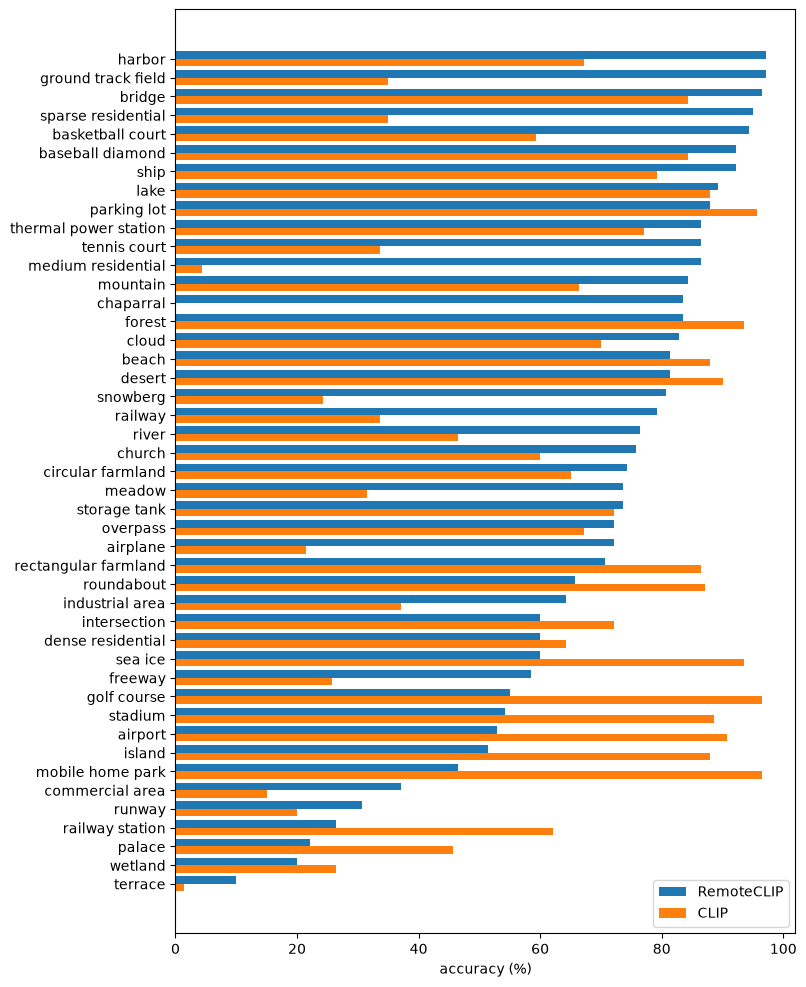

In [7]:
import matplotlib.pyplot as plt
order = rclip_pc_ens.argsort().tolist()
y = range(len(class_names))

plt.figure(figsize=(8, 12))
plt.barh([i + 0.2 for i in y], rclip_pc_ens[order], height=0.4, label="RemoteCLIP")
plt.barh([i - 0.2 for i in y], clip_pc_ens[order], height=0.4, label="CLIP")
plt.yticks(list(y), [class_names[i] for i in order])
plt.xlabel("accuracy (%)")
plt.legend()
plt.show()

**Result:** RemoteCLIP is better on average but not on every class. CLIP is clearly better on golf course, mobile home park, sea ice, airport, stadium, island, and railway station. CLIP almost completely fails on medium residential (~4%) and terrace (~1%). Terrace, wetland, and palace are hard for both models. Per-class results will be reported in the benchmark alongside overall accuracy.